# Season 0, Analyzed: 7,200 Games Between Nine Teams

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arm-2-lab/MARL-BattleGrounds/blob/main/examples/evaluate/evaluation_analysis.ipynb)

In Season 0 of MARL-BattleGrounds (MARL-BGs), nine teams played a round robin of Team Deathmatch: six deep MARL baselines, each trained for about 250 million game steps, and the three scripted bots TDM-Alpha, TDM-Beta and TDM-Gamma. Every pair of teams played 200 games on the five held-out test maps, 7,200 games in all, and every game saved all 11,192 of its measures (its full metrics).

This notebook loads those games from Hugging Face and rebuilds the paper's analysis with the public API:

1. The ladder: Elo ratings with their 95% intervals and tiers.
2. Who beats whom, and on which map.
3. The teamwork that separates strong teams from weak ones.
4. Who helps whom, class by class.
5. Every measure a game records, and how to ask your own question.

It plays no games and needs no GPU, so Colab's default runtime is enough. After the install cell, it runs in about a minute.

In [1]:
# In Colab: install MARL-BattleGrounds with the JAX build for this runtime.
# It restarts the runtime only if pip replaced a package that was already
# loaded. Anywhere else this cell does nothing; install first with
# https://marl-battlegrounds.com/#start.
import importlib.metadata
import os
import subprocess
import sys

VERSION = "1.0.2"

if "google.colab" in sys.modules:
    try:
        installed = importlib.metadata.version("marl-battlegrounds")
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed == VERSION:
        print(f"MARL-BattleGrounds {VERSION} is installed. Carry on.")
    else:
        names = {
            (d.metadata["Name"] or "").lower()
            for d in importlib.metadata.distributions()
        }
        builds = (
            ("jax-cuda13-plugin", "cuda13"),
            ("jax-cuda12-plugin", "cuda12"),
            ("libtpu", "tpu"),
        )
        build = next((choice for plugin, choice in builds if plugin in names), None)
        extras = "all" if build is None else f"all,{build}"
        package = f"marl-battlegrounds[{extras}]=={VERSION}"
        def releases() -> set[tuple[str, str]]:
            # Colab keeps some packages twice (system and pip copies), so a
            # name alone is not enough: compare each (name, version) pair.
            return {
                ((d.metadata["Name"] or "").lower(), d.version)
                for d in importlib.metadata.distributions()
            }

        before = releases()
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", package], check=True
        )
        importlib.invalidate_caches()
        changed = releases() - before
        # A restart is needed only when a module this Python already loaded
        # comes from a file pip just wrote; new packages load on first import.
        written = {
            os.path.realpath(d.locate_file(file))
            for d in importlib.metadata.distributions()
            if ((d.metadata["Name"] or "").lower(), d.version) in changed
            for file in d.files or ()
        }
        # Debugger plugins (pydevd_plugins) only change how a debugger shows
        # values, so replacing one never needs a restart.
        loaded = sorted(
            name
            for name, module in list(sys.modules.items())
            if not name.startswith("pydevd_plugins")
            and getattr(module, "__file__", None)
            and os.path.realpath(module.__file__) in written
        )
        try:
            if loaded:
                raise ImportError(f"already loaded and replaced: {', '.join(loaded)}")
            import jax

            jax.numpy.zeros(1).block_until_ready()
            print(f"Installed {package}. Carry on.")
        except Exception as reason:
            print(f"Installed {package}. Restarting the runtime now ({reason}).")
            print("When it is back, click Runtime > Run all again.")
            exit(0)  # restarts the runtime, so JAX loads the new build

## Part 1: Load Every Season 0 Game 📦

One download (about 390 MB, into `~/tdm-season-0-results`) fetches the games from the [Season 0 results dataset](https://huggingface.co/datasets/MARL-BattleGrounds/tdm-season-0-results); a second run reuses it. `marl_bgs.load_results` opens the saved tournament: the same call opens your own evaluations and tournaments.

To analyze your own saved tournament instead, set `MARL_BGS_RESULTS` to its folder (the one holding `run_details.json`) before you start the notebook. The teamwork parts need full metrics: run the tournament with `metrics="full"`.

In [2]:
import itertools
import os
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

import marl_battlegrounds as marl_bgs
from marl_battlegrounds.evaluation import metric_catalog

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 10,
    }
)
INK = "#1f3a5f"  # learned teams are filled dots; scripted bots are open dots
RHO = "\N{GREEK SMALL LETTER RHO}"  # the symbol of Spearman's rank correlation
CLASSES = {1: "Mage", 2: "Warrior", 3: "Hunter", 4: "Rogue", 5: "Priest"}

own = os.environ.get("MARL_BGS_RESULTS")
if own:
    folder, names, scripted = Path(own).expanduser(), {}, set()
else:
    from huggingface_hub import snapshot_download

    data = Path.home() / "tdm-season-0-results"  # plain files, not cache links
    snapshot_download(
        "MARL-BattleGrounds/tdm-season-0-results",
        repo_type="dataset",
        allow_patterns=["season-0-games/*", "season-0-ratings/ratings.csv"],
        local_dir=data,
    )
    folder = data / "season-0-games"
    published = pd.read_csv(data / "season-0-ratings/ratings.csv")
    names = dict(zip(published["entrant"], published["label"], strict=True))
    scripted = set(published.loc[published["method"] == "scripted", "entrant"])


def label(entrant: str) -> str:
    """Return a saved entrant's display name, such as "Recurrent IPPO" or "TDM-Alpha".

    Season 0 names come from the published ratings; any other name is kept.
    """
    name = names.get(entrant, entrant)
    return "TDM-" + name[4:].title() if name.startswith("tdm-") else name


season = marl_bgs.load_results(folder)
games = pd.DataFrame(season.table("matches"))
teams = sorted({*games["team_a_policy"], *games["team_b_policy"]})
maps = sorted(games["map_id"].unique())
print(f"{len(games):,} games between {len(teams)} teams on maps", *maps)

7,200 games between 9 teams on maps 47 48 49 50 51


## Part 2: The Ladder 🏆

Which method leads? A joint Elo fit of all games rates every team, with a 95% interval from resampling whole pairs of games. The average rating is 1,200, and an Elo lead of 200 means winning about 76% of decisive games. Tiers are labels beside the rating: 200-Elo bands from Iron to Grandmaster, each with five 40-Elo divisions, 5 (lowest) to 1 (highest). Point margin, kills and deaths are averages per game.

Rank,Team,Elo,95% Interval,Tier,Wins,Draws,Losses,Point Margin,Kills,Deaths
1,Recurrent IPPO,"1,441","1,426 to 1,458",Platinum 4,1038,336,226,+5.21,18.0,12.7
2,PQN-VDN,"1,358","1,349 to 1,368",Gold 2,867,419,314,+1.30,14.7,12.5
3,Recurrent MAPPO,"1,304","1,288 to 1,322",Gold 3,825,319,456,+2.29,16.9,14.8
4,QMIX,"1,300","1,288 to 1,313",Gold 3,792,371,437,+0.64,15.8,15.5
5,Feedforward IPPO,"1,240","1,225 to 1,255",Gold 4,639,463,498,+1.75,15.9,14.1
6,Feedforward MAPPO,"1,140","1,126 to 1,155",Silver 2,458,466,676,-2.69,13.1,14.2
7,TDM-Beta,"1,043","1,030 to 1,055",Silver 4,485,77,1038,-2.99,14.7,18.1
8,TDM-Gamma,"1,000","986 to 1,014",Silver 5,435,40,1125,-2.39,15.1,18.4
9,TDM-Alpha,974,959 to 988,Bronze 1,394,43,1163,-3.11,14.5,18.3


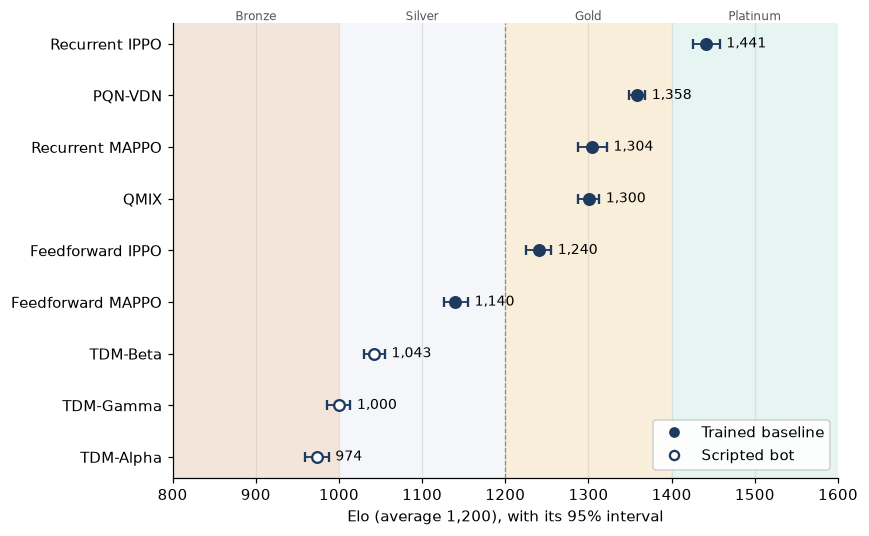

Recurrent IPPO leads with 1,441 Elo (Platinum 4): it would win about 80%
of decisive games against a team of average strength.


In [3]:
TIERS = {600: "Iron", 800: "Bronze", 1000: "Silver", 1200: "Gold", 1400: "Platinum"}
TIERS |= {1600: "Diamond", 1800: "Master", 2000: "Grandmaster"}
METAL = {"Iron": "#98A1B2", "Bronze": "#C98A5A", "Silver": "#CDD6E4", "Gold": "#E2B455"}
METAL |= {"Platinum": "#8FD3C6", "Diamond": "#9ED2F5", "Master": "#A597F2"}
METAL |= {"Grandmaster": "#FFE2A0"}


def tier(elo: float) -> str:
    """Return the tier and division of an Elo, such as "Platinum 4".

    The Elo is rounded first. Bands are 200 Elo wide with five 40-Elo divisions,
    5 (lowest) to 1; every Elo below 640 is Iron 5, and Grandmaster (2,000 and
    above) has no divisions.
    """
    whole = round(elo)
    if whole >= 2000:
        return "Grandmaster"
    band = max(600, min(1800, whole // 200 * 200))
    return f"{TIERS[band]} {min(5, 5 - (whole - band) // 40)}"


def tier_bands(axis: plt.Axes, low: float, high: float, names: bool = True) -> None:
    """Shade the tier bands from Elo low to high across an axis.

    names=True writes each band's tier name above the axis; a dashed line marks
    the average Elo, 1,200, and the axis is limited to low through high.
    """
    for start in range(600, 2200, 200):
        left, right = max(start, low), min(start + 200, high)
        if left < right:
            axis.axvspan(left, right, color=METAL[TIERS[start]], alpha=0.22, lw=0)
            if names:
                axis.text(
                    (left + right) / 2,
                    1.0,
                    TIERS[start],
                    transform=axis.get_xaxis_transform(),
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    color="#555555",
                )
    if low < 1200 < high:
        axis.axvline(1200, color="#888888", ls="--", lw=0.8)
    axis.set_xlim(low, high)


rated = pd.DataFrame(season.table("tournament_results"))
results = pd.DataFrame(
    season.system_metrics(
        "priority_metrics",
        columns=["score_difference", "team_a_kills", "team_a_deaths"],
    )
)
ladder = rated.merge(
    results, left_on="policy", right_on="system_name", suffixes=("", "_")
)
ladder = ladder.sort_values("elo", ascending=False).reset_index(drop=True)
ladder["team"] = ladder["policy"].map(label)
# A tournament too small to resample has no interval; its bars then have no width.
ladder["low"] = ladder["elo_ci_low"].fillna(ladder["elo"])
ladder["high"] = ladder["elo_ci_high"].fillna(ladder["elo"])
table = pd.DataFrame(
    {
        "Rank": range(1, len(ladder) + 1),
        "Team": ladder["team"],
        "Elo": ladder["elo"].round().astype(int),
        "95% Interval": [
            f"{low:,.0f} to {high:,.0f}" if np.isfinite(low) else "Not available"
            for low, high in zip(
                ladder["elo_ci_low"], ladder["elo_ci_high"], strict=True
            )
        ],
        "Tier": ladder["elo"].map(tier),
        "Wins": ladder["wins"],
        "Draws": ladder["draws"],
        "Losses": ladder["losses"],
        "Point Margin": ladder["score_difference"],
        "Kills": ladder["team_a_kills"],
        "Deaths": ladder["team_a_deaths"],
    }
)
display(
    table.style.hide(axis="index")
    .format(
        {
            "Elo": "{:,}",
            "Point Margin": "{:+.2f}",
            "Kills": "{:.1f}",
            "Deaths": "{:.1f}",
        }
    )
    .map(lambda name: f"background-color: {METAL[name.split()[0]]}55", subset="Tier")
)

fig, axis = plt.subplots(figsize=(8, 0.42 * len(ladder) + 1.2))
low = (ladder["low"].min() - 60) // 100 * 100
high = (ladder["high"].max() + 160) // 100 * 100
tier_bands(axis, low, high)
for row, entry in ladder.iterrows():
    filled = entry["policy"] not in scripted
    axis.errorbar(
        entry["elo"],
        row,
        xerr=[[entry["elo"] - entry["low"]], [entry["high"] - entry["elo"]]],
        fmt="o",
        ms=7,
        color=INK,
        mfc=INK if filled else "white",
        mew=1.5,
        capsize=3,
        lw=1.2,
    )
    axis.text(entry["high"] + 8, row, f"{entry['elo']:,.0f}", va="center", fontsize=9)
axis.set_yticks(range(len(ladder)), ladder["team"])
axis.invert_yaxis()
axis.set_xlabel("Elo (average 1,200), with its 95% interval")
axis.grid(axis="x", alpha=0.3)
axis.legend(
    handles=[
        plt.Line2D([], [], ls="", marker="o", color=INK, label="Trained baseline"),
        plt.Line2D(
            [],
            [],
            ls="",
            marker="o",
            color=INK,
            mfc="white",
            mew=1.5,
            label="Scripted bot",
        ),
    ],
    loc="lower right",
    framealpha=0.9,
)
plt.tight_layout()
plt.show()

leader = ladder.iloc[0]
beats = 1 / (1 + 10 ** (-(leader["elo"] - 1200) / 400))
name, elo = leader["team"], leader["elo"]
print(f"{name} leads with {elo:,.0f} Elo ({tier(elo)}): it would win about {beats:.0%}")
print("of decisive games against a team of average strength.")

## Part 3: Who Beats Whom, and Where ⚔️

Each cell gives the row team's average point margin per game against the column team over their games: blue when the row team scores more, red when it scores less. A strong team beats the field, and a rock-paper-scissors loop would show as blue and red cells out of rank order. The second chart splits each team's expected score (wins plus half the draws) by test map: 50% is an even record.

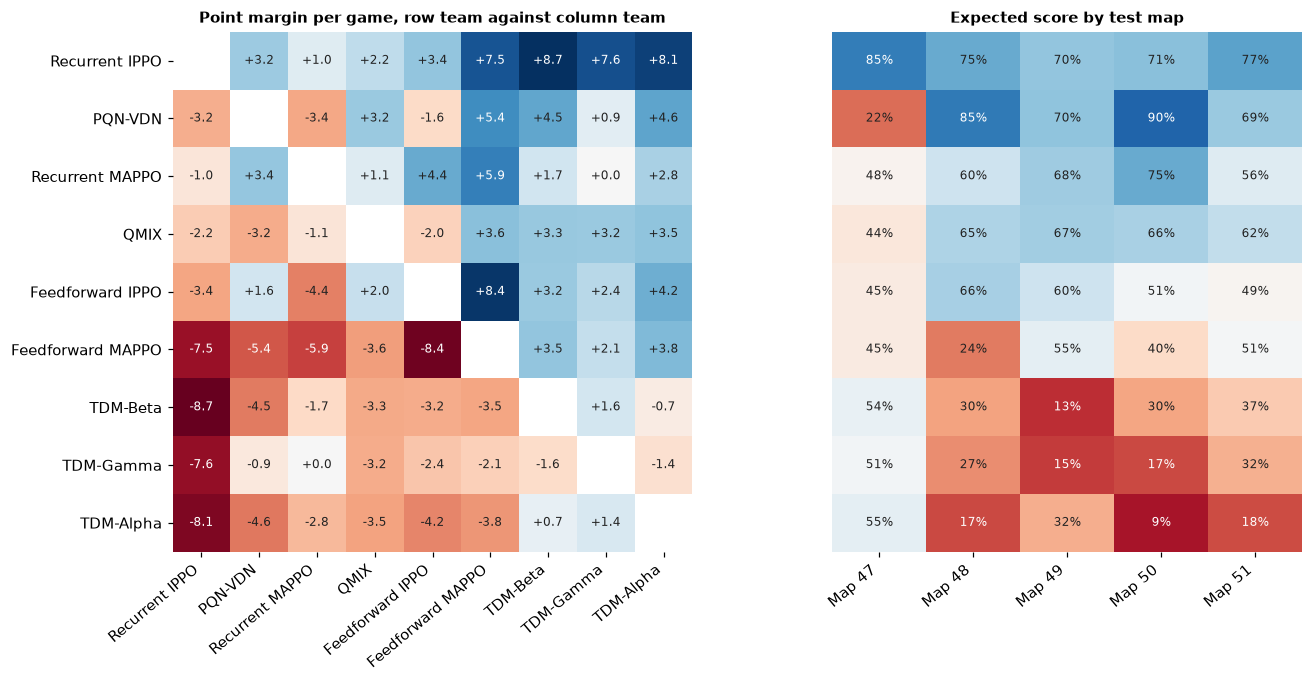

The map matters most for PQN-VDN: from 22% on map 47
to 90% on map 50.


In [4]:
order = list(ladder["team"])
pairs = pd.DataFrame(season.head_to_head())
pairs["team"], pairs["opponent"] = (
    pairs["system_name"].map(label),
    pairs["opponent_name"].map(label),
)
margins = pairs.pivot(
    index="team", columns="opponent", values="mean_point_margin"
).reindex(index=order, columns=order)

by_map = pd.DataFrame(season.table("map_results"))
by_map["team"] = by_map["policy"].map(label)
scores = by_map.pivot(index="team", columns="map_id", values="expected_score").reindex(
    index=order
)

fig, (left, right) = plt.subplots(
    1,
    2,
    figsize=(13, 0.5 * len(order) + 1.8),
    gridspec_kw={"width_ratios": [len(order), 0.8 * len(scores.columns) + 1]},
)
limit = float(np.nanmax(np.abs(margins.to_numpy())))
left.imshow(margins, cmap="RdBu", norm=TwoSlopeNorm(0, -limit, limit))
for (i, j), value in np.ndenumerate(margins.to_numpy()):
    if np.isfinite(value):
        left.text(
            j,
            i,
            f"{value:+.1f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) > 0.55 * limit else "#222222",
        )
left.set_xticks(range(len(order)), order, rotation=40, ha="right")
left.set_yticks(range(len(order)), order)
left.set_title("Point margin per game, row team against column team")
left.spines[:].set_visible(False)

right.imshow(scores, cmap="RdBu", norm=TwoSlopeNorm(0.5, 0, 1), aspect="auto")
for (i, j), value in np.ndenumerate(scores.to_numpy()):
    right.text(
        j,
        i,
        f"{value:.0%}",
        ha="center",
        va="center",
        fontsize=8,
        color="white" if abs(value - 0.5) > 0.3 else "#222222",
    )
right.set_xticks(
    range(len(scores.columns)),
    [f"Map {m}" for m in scores.columns],
    rotation=40,
    ha="right",
)
right.set_yticks([])
right.set_title("Expected score by test map")
right.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

spread = scores.max(axis=1) - scores.min(axis=1)
team = spread.idxmax()
worst, best = scores.loc[team].idxmin(), scores.loc[team].idxmax()
low, high = scores.loc[team, worst], scores.loc[team, best]
print(f"The map matters most for {team}: from {low:.0%} on map {worst}")
print(f"to {high:.0%} on map {best}.")

## Part 4: What Separates Strong Teams From Weak Ones 🤝

`system_metrics` pools each team's games from its own side: every team is shown as Team A, and each measure combines its games by the metric catalog's rule, with a 95% interval from resampling whole pairs of games. `ratios=` adds measures that divide one total by another, such as damage per 100 ticks, so longer games do not count more.

For each measure, ρ is Spearman's rank correlation with Elo: +1 when every stronger team has more of it. Its exact p-value is the share of all orderings of the ratings that correlate at least as strongly. These six are the paper's figure: strong teams stand closer together, so their auras pay off; they cash in each other's setups; and their Priests heal the teammate who needs it. Attacking at the same time does not follow Elo.

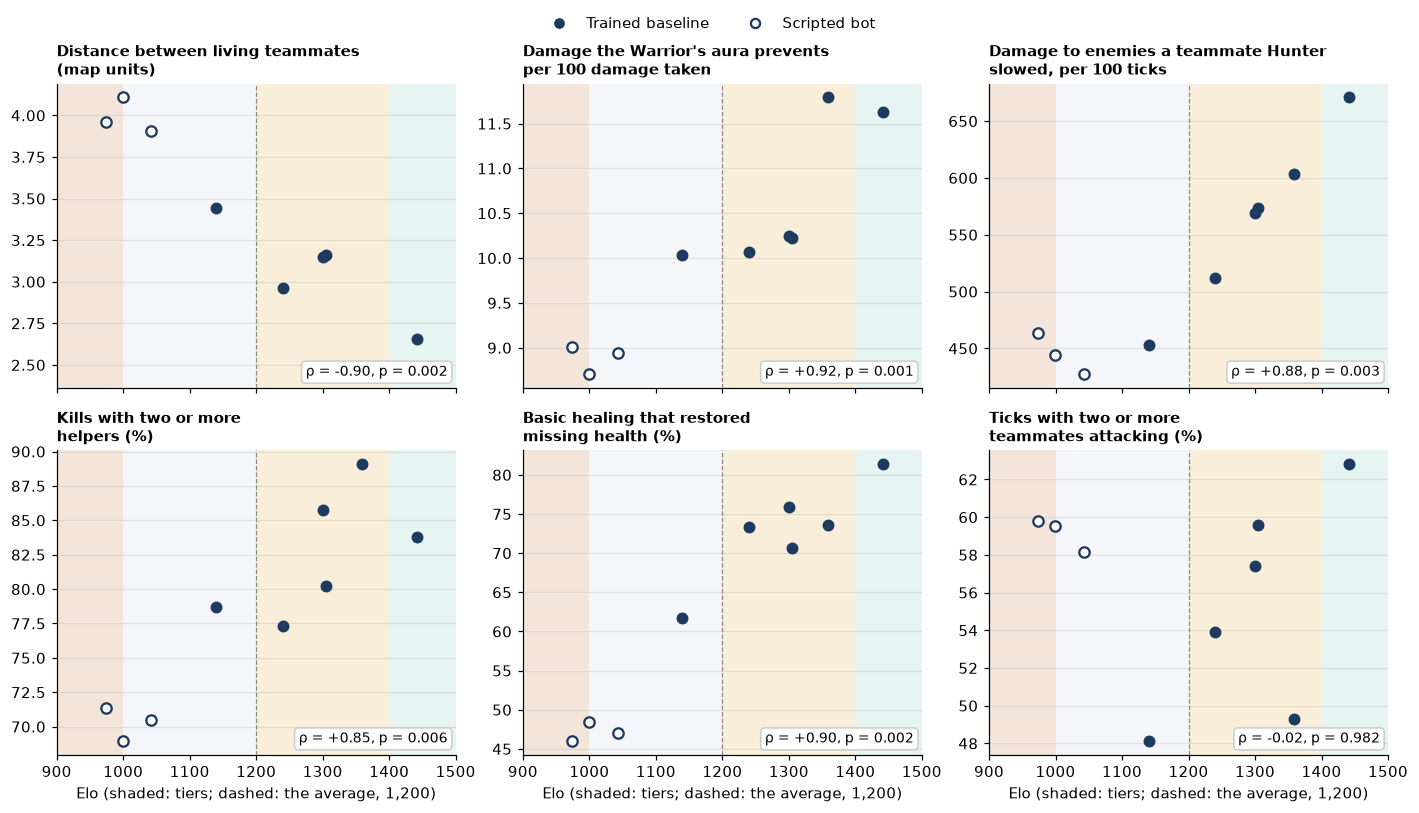

team,Recurrent IPPO,PQN-VDN,Recurrent MAPPO,QMIX,Feedforward IPPO,Feedforward MAPPO,TDM-Beta,TDM-Gamma,TDM-Alpha,ρ with Elo,Exact p
Distance between living teammates (map units),2.66,2.44,3.16,3.15,2.96,3.45,3.90,4.11,3.96,-0.90,0.002
Damage the Warrior's aura prevents per 100 damage taken,11.63,11.79,10.23,10.25,10.07,10.03,8.94,8.71,9.01,+0.92,0.001
"Damage to enemies a teammate Hunter slowed, per 100 ticks",670.80,603.73,573.20,569.39,512.11,453.25,427.42,444.08,463.21,+0.88,0.003
Kills with two or more helpers (%),83.77,89.08,80.26,85.73,77.33,78.72,70.49,68.97,71.34,+0.85,0.006
Basic healing that restored missing health (%),81.36,73.63,70.62,75.96,73.36,61.74,47.03,48.43,46.03,+0.90,0.002
Ticks with two or more teammates attacking (%),62.81,49.31,59.57,57.44,53.90,48.14,58.13,59.54,59.80,-0.02,0.982
Kills per 100 ticks,7.50,6.02,7.10,6.52,6.39,5.21,6.91,7.11,7.06,+0.02,0.982
Deaths per 100 ticks,5.31,5.09,6.22,6.40,5.67,5.63,8.51,8.71,8.92,-0.83,0.008


Stronger teams do not kill faster (ρ = +0.02, p = 0.982); they die less (ρ = -0.83, p = 0.008).


In [5]:
@cache
def orderings(count: int) -> np.ndarray:
    """Return every ordering of count items, as rows of an integer array.

    Above nine items it returns 100,000 random orderings from a fixed seed
    instead, because the exact list grows too long (9 items have 362,880).
    """
    if count <= 9:
        return np.array(list(itertools.permutations(range(count))))
    return np.random.default_rng(0).permuted(
        np.tile(np.arange(count), (100_000, 1)), axis=1
    )


def rank_correlation(values: pd.Series, elo: pd.Series) -> tuple[float, float]:
    """Return Spearman's rank correlation of values with Elo, and its exact p-value.

    Teams with a missing value are left out, and tied values share their average
    rank. The two-sided p-value is the share of orderings of the ratings that
    correlate at least as strongly. Fewer than three teams with a value, or
    values that are all equal, give NaN for both.
    """
    kept = values.notna().to_numpy()
    x = values[kept].rank().to_numpy()
    y = elo[kept].rank().to_numpy()
    if len(x) < 3 or x.std() == 0:
        return float("nan"), float("nan")
    zx, zy = (x - x.mean()) / x.std(), (y - y.mean()) / y.std()
    rho = float(np.mean(zx * zy))
    shuffled = zy[orderings(len(y))]
    return rho, float(np.mean(np.abs(shuffled @ zx / len(x)) >= abs(rho) - 1e-12))


RATIOS = {
    "warrior_aura_protection": (
        "team_a_damage_prevented_by_warrior_aura",
        "team_a_damage_received",
    ),
    "slowed_damage_per_tick": (
        "team_a_damage_to_hunter_basic_slow_recipient",
        "episode_length",
    ),
    "attack_together_per_tick": ("team_a_focus_fire_steps", "episode_length"),
    "kills_per_tick": ("team_a_kills", "episode_length"),
    "deaths_per_tick": ("team_a_deaths", "episode_length"),
}
MEASURES = {  # column or ratio: (title, scale)
    "team_a_ally_distance_mean": ("Distance between living teammates\n(map units)", 1),
    "warrior_aura_protection": (
        "Damage the Warrior's aura prevents\nper 100 damage taken",
        100,
    ),
    "slowed_damage_per_tick": (
        "Damage to enemies a teammate Hunter\nslowed, per 100 ticks",
        100,
    ),
    "team_a_multi_contributor_kill_fraction": (
        "Kills with two or more\nhelpers (%)",
        100,
    ),
    "team_a_basic_effective_healing_fraction": (
        "Basic healing that restored\nmissing health (%)",
        100,
    ),
    "attack_together_per_tick": (
        "Ticks with two or more\nteammates attacking (%)",
        100,
    ),
}
EXTRA = {
    "kills_per_tick": "Kills per 100 ticks",
    "deaths_per_tick": "Deaths per 100 ticks",
}
teamwork = pd.DataFrame(
    season.system_metrics(
        "full_metrics",
        columns=[
            "team_a_ally_distance_mean",
            "team_a_multi_contributor_kill_fraction",
            "team_a_basic_effective_healing_fraction",
        ],
        ratios=RATIOS,
    )
).sort_values("elo", ascending=False)
teamwork["team"] = teamwork["system_name"].map(label)
learned = ~teamwork["system_name"].isin(scripted)

fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True)
low = (teamwork["elo"].min() - 60) // 100 * 100
high = (teamwork["elo"].max() + 100) // 100 * 100
trends = {}
for axis, (column, (title, scale)) in zip(axes.flat, MEASURES.items(), strict=True):
    values = teamwork[column] * scale
    rho, p = rank_correlation(values, teamwork["elo"])
    trends[title.replace("\n", " ")] = (rho, p)
    tier_bands(axis, low, high, names=False)
    axis.scatter(teamwork["elo"][learned], values[learned], s=46, color=INK, zorder=3)
    axis.scatter(
        teamwork["elo"][~learned],
        values[~learned],
        s=46,
        facecolor="white",
        edgecolor=INK,
        lw=1.5,
        zorder=3,
    )
    axis.set_title(title, loc="left")
    axis.text(
        0.98,
        0.04,
        f"{RHO} = {rho:+.2f}, p = {p:.3f}",
        transform=axis.transAxes,
        ha="right",
        fontsize=9,
        bbox={"boxstyle": "round", "fc": "white", "ec": "#cccccc"},
    )
    axis.grid(axis="y", alpha=0.3)
for axis in axes[1]:
    axis.set_xlabel("Elo (shaded: tiers; dashed: the average, 1,200)")
fig.legend(
    handles=[
        plt.Line2D([], [], ls="", marker="o", color=INK, label="Trained baseline"),
        plt.Line2D(
            [],
            [],
            ls="",
            marker="o",
            color=INK,
            mfc="white",
            mew=1.5,
            label="Scripted bot",
        ),
    ],
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.03),
)
plt.tight_layout()
plt.show()

shown = {
    title.replace("\n", " "): teamwork[column] * scale
    for column, (title, scale) in MEASURES.items()
}
shown |= {title: teamwork[column] * 100 for column, title in EXTRA.items()}
values = pd.DataFrame(shown).set_axis(teamwork["team"])
for title in EXTRA.values():
    trends[title] = rank_correlation(values[title], teamwork.set_index("team")["elo"])
values.loc[f"{RHO} with Elo"] = [trends[title][0] for title in values.columns]
values.loc["Exact p"] = [trends[title][1] for title in values.columns]
display(
    values.T.style.format("{:.2f}")
    .format("{:+.2f}", subset=[f"{RHO} with Elo"])
    .format("{:.3f}", subset=["Exact p"])
)
kills, deaths = trends["Kills per 100 ticks"], trends["Deaths per 100 ticks"]
print(
    f"Stronger teams do not kill faster ({RHO} = {kills[0]:+.2f}, p = {kills[1]:.3f}); "
    f"they die less ({RHO} = {deaths[0]:+.2f}, p = {deaths[1]:.3f})."
)

## Part 5: Who Helps Whom, Class by Class 🧙

The full metrics record who did what to whom: every agent's damage to every enemy, its share in every kill, and every heal to every teammate. In the Season 0 roster, agents 0-4 are Mage, Warrior, Hunter, Rogue and Priest, and `system_metrics` always shows a team's own agents as 0-4 and its enemies as 5-9. The charts compare the top-rated team with the lowest-rated one: where each class's damage goes (the Priest heals and deals no damage, so it has no row), and whom the Priest's useful healing reaches.

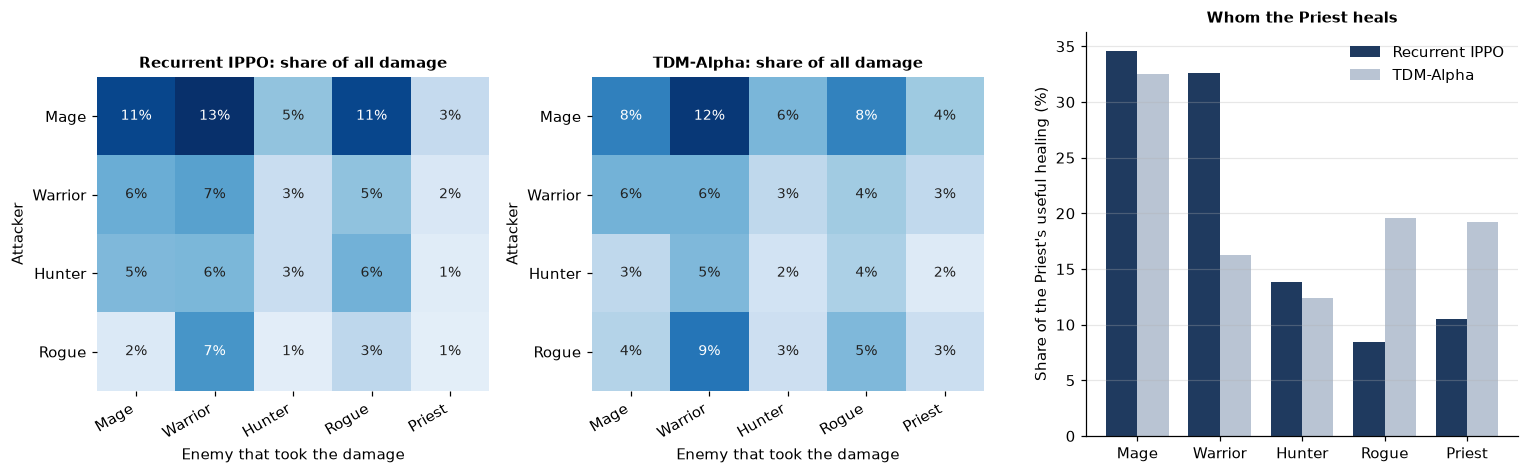

In [6]:
damage = [f"agent_{a}_to_agent_{b}_damage_done" for a in range(5) for b in range(5, 10)]
healing = [f"agent_4_to_agent_{b}_effective_healing_done" for b in range(5)]
classes = pd.DataFrame(season.system_metrics("full_metrics", columns=damage + healing))
classes = classes.sort_values("elo", ascending=False).reset_index(drop=True)
roster = [
    CLASSES.get(int(classes[f"agent_{a}_class_id"][0]), f"Agent {a}") for a in range(5)
]
top, bottom = classes.iloc[0], classes.iloc[-1]

fig, axes = plt.subplots(
    1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.1]}
)
attackers = [
    a for a in range(5) if classes[damage[5 * a : 5 * a + 5]].to_numpy().sum() > 0
]
for axis, team in zip(axes[:2], (top, bottom), strict=True):
    grid = team[damage].to_numpy(float).reshape(5, 5)[attackers]
    share = grid / grid.sum()
    axis.imshow(share, cmap="Blues", vmin=0, vmax=0.12)
    for (i, j), value in np.ndenumerate(share):
        axis.text(
            j,
            i,
            f"{value:.0%}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > 0.07 else "#222222",
        )
    axis.set_xticks(range(5), roster, rotation=30, ha="right")
    axis.set_yticks(range(len(attackers)), [roster[a] for a in attackers])
    axis.set_xlabel("Enemy that took the damage")
    axis.set_ylabel("Attacker")
    axis.set_title(f"{label(team['system_name'])}: share of all damage")
    axis.spines[:].set_visible(False)

width = 0.38
for offset, team, color in ((-width / 2, top, INK), (width / 2, bottom, "#B9C4D3")):
    heals = team[healing].to_numpy(float)
    axes[2].bar(
        np.arange(5) + offset,
        100 * heals / heals.sum(),
        width,
        color=color,
        label=label(team["system_name"]),
    )
axes[2].set_xticks(range(5), roster)
axes[2].set_ylabel("Share of the Priest's useful healing (%)")
axes[2].set_title("Whom the Priest heals")
axes[2].legend(frameon=False)
axes[2].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Part 6: 11,192 Measures in Every Game 📊

The metric catalog (`marl_battlegrounds.evaluation.metric_catalog`) names and explains every measure a game records, in 28 topics. Most of them record who did what to whom: one agent acting on one teammate or enemy.

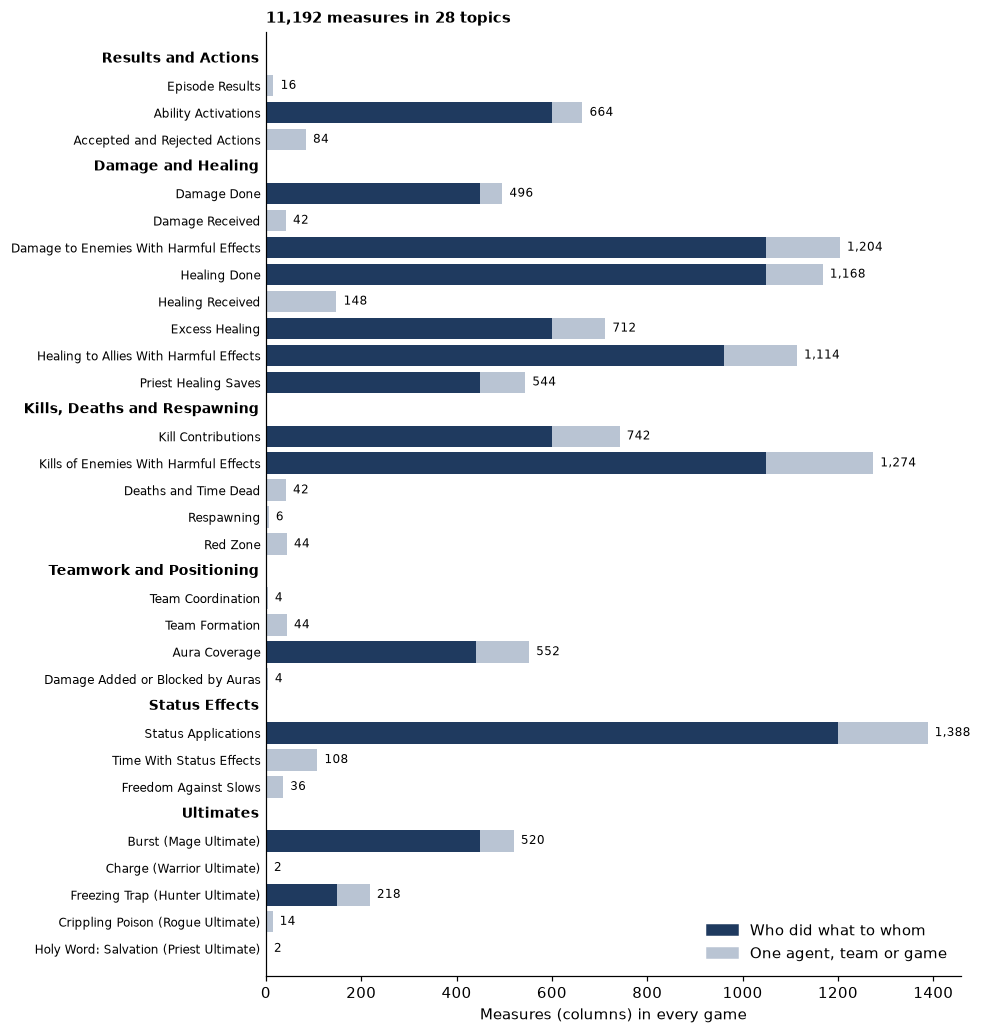

In [7]:
topics = {topic.name: topic for topic in metric_catalog.METRIC_TOPICS}
counts = pd.DataFrame(
    [
        (
            metric_catalog.metric_primary_location(column)[0],
            column.scope == "source_recipient",
        )
        for column in metric_catalog.METRIC_COLUMNS
    ],
    columns=["topic", "directed"],
)
per_topic = counts.groupby("topic", sort=False)["directed"].agg(["size", "sum"])
per_topic = per_topic.reindex([name for name in topics if name in per_topic.index])

fig, axis = plt.subplots(figsize=(9, 9.5))
row, ticks, section = 0, [], None
for name, entry in per_topic.iterrows():
    if topics[name].section != section:
        section = topics[name].section
        axis.text(
            -15, row, section, ha="right", va="center", fontsize=9, fontweight="bold"
        )
        row += 1
    axis.barh(row, entry["sum"], color=INK)
    axis.barh(row, entry["size"] - entry["sum"], left=entry["sum"], color="#B9C4D3")
    axis.text(entry["size"] + 15, row, f"{entry['size']:,}", va="center", fontsize=8)
    ticks.append((row, topics[name].label))
    row += 1
axis.set_yticks([r for r, _ in ticks], [text for _, text in ticks], fontsize=8)
axis.tick_params(axis="y", length=0)
axis.set_ylim(row, -1)
axis.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=INK, label="Who did what to whom"),
        plt.Rectangle((0, 0), 1, 1, color="#B9C4D3", label="One agent, team or game"),
    ],
    frameon=False,
    loc="lower right",
)
axis.set_xlabel("Measures (columns) in every game")
axis.set_title(
    f"{len(metric_catalog.METRIC_COLUMNS):,} measures in {len(per_topic)} topics",
    loc="left",
)
plt.tight_layout()
plt.show()

## Part 7: Ask Your Own Question 🔎

Pick any word: the cell lists the team measures whose name or meaning contains it. Then set `QUESTION` to one of them (or any column the catalog names) to draw it against Elo, with its 95% intervals and its rank correlation. Try `"freedom"`, `"trap"`, `"red zone"` or `"ultimate"`.

Column,Meaning
team_a_rescue_opportunities,How many times incoming damage would kill an ally and Team A had enough Priest healing ready and allowed to save them. Several Priests may be needed. Each threatened ally counts once per tick. Each ally is checked separately. This does not mean the Priests could save all threatened allies at once.
team_a_rescues,How many times Priest healing on Team A kept an ally alive when that tick's damage would otherwise kill them. Each saved ally counts once per tick.
team_a_rescue_rate,How often Team A saved an ally when its available Priest healing could have saved that ally from death.
team_a_basic_rescues,How many times Team A helped save allies from death. Each rescue counts once even if several teammates helped. Priest healing must keep the ally alive when that tick's damage would otherwise kill them. At least part of the helping Priest's heal must be useful. Several Priests can help; one Priest may not have enough healing to save the ally alone. Counts only help from Basic healing.
team_a_basic_rescue_fraction,"What share of Team A's saves had help from Basic healing. Count each saved ally once per tick, even if several Priests helped. One save can have Basic and Ultimate help, so those shares can add up to more than 100%."
team_a_ultimate_rescues,How many rescues Team A got with help from an Ultimate on that tick. Each rescue counts once even if several teammates helped.
team_a_ultimate_rescue_fraction,"What share of Team A's rescues had help from an Ultimate. This shows Ultimate use, not whether using Ultimates more often is better."


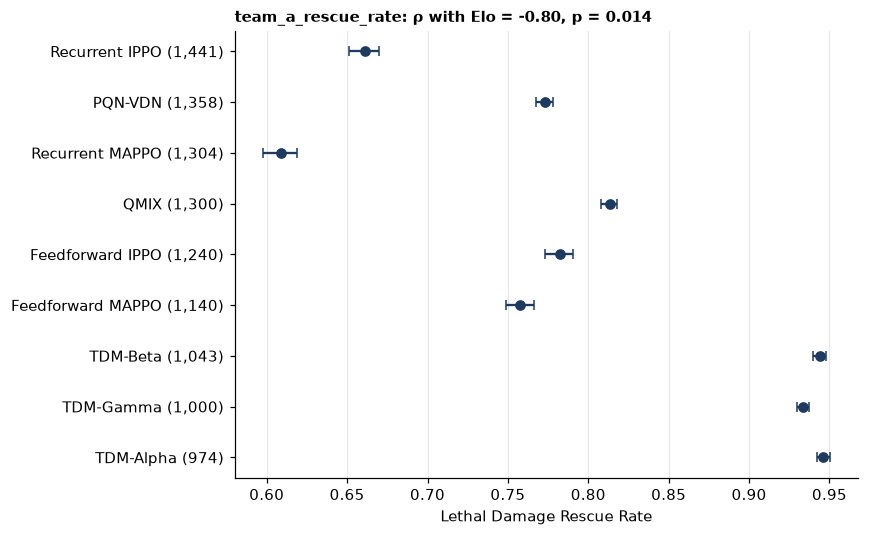

How often Team A saved an ally when its available Priest healing could have saved that ally from death.


In [8]:
WORD = "rescue"
found = [
    column
    for column in metric_catalog.METRIC_COLUMNS
    if column.scope == "team"
    and column.name.startswith("team_a_")
    and WORD.lower()
    in f"{column.name} {column.label} {column.description}".lower().replace("_", " ")
]
display(
    pd.DataFrame(
        [(c.name, c.description) for c in found[:10]], columns=["Column", "Meaning"]
    ).style.hide(axis="index")
)
QUESTION = "team_a_rescue_rate"  # or any column above

answer = pd.DataFrame(
    season.system_metrics("full_metrics", columns=[QUESTION])
).sort_values("elo")
answer["team"] = answer["system_name"].map(label)
rho, p = rank_correlation(answer[QUESTION], answer["elo"])
fig, axis = plt.subplots(figsize=(8, 0.42 * len(answer) + 1.2))
rows = range(len(answer))
below = (answer[QUESTION] - answer[f"{QUESTION}_ci_low"]).fillna(0)
above = (answer[f"{QUESTION}_ci_high"] - answer[QUESTION]).fillna(0)
axis.errorbar(
    answer[QUESTION], rows, xerr=[below, above], fmt="o", color=INK, capsize=3
)
axis.set_yticks(
    rows,
    [
        f"{team} ({elo:,.0f})"
        for team, elo in zip(answer["team"], answer["elo"], strict=True)
    ],
)
axis.set_xlabel(metric_catalog.METRIC_COLUMNS_BY_NAME[QUESTION].label)
axis.set_title(f"{QUESTION}: {RHO} with Elo = {rho:+.2f}, p = {p:.3f}", loc="left")
axis.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
print(metric_catalog.METRIC_COLUMNS_BY_NAME[QUESTION].description)

## Next

- Play your own games with full metrics: [the evaluation guide](https://github.com/arm-2-lab/MARL-BattleGrounds/blob/main/docs/evaluation.md) and [the tournaments guide](https://github.com/arm-2-lab/MARL-BattleGrounds/blob/main/docs/tournaments.md). Open the saved folder here with `MARL_BGS_RESULTS`.
- Every measure and how it is counted: [the metrics guide](https://github.com/arm-2-lab/MARL-BattleGrounds/blob/main/docs/metrics.md).
- The paper's complete teamwork study, with corrections for testing 138 measures at once: `python -m marl_battlegrounds.experiments.tournament_analysis`.
- Watch the games in the analytical Replay Viewer, on your own computer: https://marl-battlegrounds.com/#start.
- The walkthrough (the API, speed, training and the trained teams): [open it in Colab](https://colab.research.google.com/github/arm-2-lab/MARL-BattleGrounds/blob/main/examples/quickstart.ipynb).